### FP / FN Analysis – Fire and Smoke Detection (CSC 403, Group 2)

This notebook analyses the false positives and missed detections of the six models trained on the **cleaned** dataset (three architectures × two random seeds), evaluated on the **cleaned test split** (782 images). Results are reported for each seed and as mean ± standard deviation across seeds, for the full test split and for each challenging condition.

Two confidence-threshold methods are reported separately:
- **Method A – fixed threshold:** a confidence threshold of 0.25 is applied to every run.
- **Method B – validation best-F1 threshold:** for each run, the confidence threshold that maximizes the mean F1-score of the fire and smoke classes on the **cleaned validation split** (761 images) is selected, fixed, and applied to the test split.

#### Settings

In [1]:
RUN_ROOT  = "/content/drive/MyDrive/all_runs/all_runs_clean"
OUT_DIR   = "/content/drive/MyDrive/results_fpfn"
INPUT_DIR = "/content/drive/MyDrive/analysis_inputs"
ANNOTATOR_FILES  = ("annotator_A.xlsx", "annotator_B.xlsx")
ADJUDICATED_FILE = "disagreements_adjudicated.xlsx"

CLEAN_DATASET_LINK = "https://drive.google.com/file/d/1nBbOcdJcH4HDuX8eBl1lyeXgw09k_jwI/view?usp=sharing"
CLEAN_ZIP_HINT     = "dataset_final_v8"
CLEAN_MD5          = "e4f0e4fc1bbe96ce7ac61d91151edf21"
CLEAN_BYTES        = 414447684
CLEAN_ZIP_PATH     = "/content/dataset_final_v8.zip"
CLEAN_EXTRACT_DIR  = "/content/dataset_final_v8_eval"

MODEL_ORDER = ["RT-DETR-L", "YOLO11s", "YOLOv10s"]
SEEDS       = [0, 1]
CLASS_NAMES = ["fire", "smoke"]
CATEGORIES  = ["Weak / Diffuse Smoke", "Complex Background", "Poor Illumination"]
EXPECTED_TEST_IMAGES = 782
EXPECTED_VAL_IMAGES  = 761
EXPECTED_SAMPLE      = 197

CONF_THRESHOLD = 0.25
PRED_CONF      = 0.001
MAX_DET        = 300
THRESH_GRID    = (0.01, 0.99, 0.01)
IOU_MATCH      = 0.50
LOC_IOU_MIN    = 0.10
NMS_IOU        = 0.70
SMALL_AREA_PX  = 32 * 32
IMGSZ          = 640
PRED_BATCH     = 8
EXAMPLE_SEED   = 0
N_EXAMPLES     = 4
ULTRALYTICS_SPEC = "ultralytics==8.4.173"

#### Setup

In [2]:
import os, re, sys, json, time, shutil, hashlib, zipfile, subprocess, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
pd.set_option("display.width", 220, "display.max_columns", 60)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception as e:
    print("Drive not mounted:", type(e).__name__, e)
    IN_COLAB = False

OUT = Path(OUT_DIR); FIG = OUT / "figures"; TAB = OUT / "tables"; CACHE = OUT / "cache"; EXM = OUT / "examples"
for d in (OUT, FIG, TAB, CACHE, EXM):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"RT-DETR-L": "#3b6ea8", "YOLO11s": "#d9822b", "YOLOv10s": "#4f9a4f"}

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index)

def pm(values, d=3):
    v = [float(x) for x in values if x is not None and x == x]
    if not v: return "-"
    if len(v) == 1: return f"{v[0]:.{d}f} (1 seed)"
    return f"{np.mean(v):.{d}f} ± {np.std(v, ddof=1):.{d}f}"

def model_sort(models):
    return [m for m in MODEL_ORDER if m in set(models)] + sorted(set(models) - set(MODEL_ORDER))

def canon_model(name):
    n = re.sub(r"[^a-z0-9]", "", str(name).lower())
    for m in MODEL_ORDER:
        if re.sub(r"[^a-z0-9]", "", m.lower()) == n: return m
    return str(name)

Mounted at /content/drive


#### 1. Cleaned runs

In [3]:
RUNS = {}
rows = []
for rj in sorted(Path(RUN_ROOT).glob("*/report.json")):
    R = json.loads(rj.read_text())
    key = (canon_model(R.get("model")), R.get("seed"))
    best = rj.parent / "train" / "run" / "weights" / "best.pt"
    if key in RUNS:
        print(f"WARNING: two folders for {key[0]} seed {key[1]}: {rj.parent.name} is ignored"); continue
    if not best.exists():
        print(f"WARNING: {rj.parent.name} has no best.pt - skipped"); continue
    RUNS[key] = best
    rows.append({"model": key[0], "seed": key[1], "folder": rj.parent.name,
                 "NaN batches": R.get("nonfinite_training_batches", 0),
                 "best epoch": ((R.get("validation") or {}).get("best_epoch") or {}).get("epoch"),
                 "test mAP50 (report)": round((R.get("test") or {}).get("mAP50", float("nan")), 4)})
runs = pd.DataFrame(rows)
runs["r"] = runs.model.map({m: i for i, m in enumerate(MODEL_ORDER)}); runs = runs.sort_values(["r", "seed"]).drop(columns="r")
print(runs.to_string(index=False))
print(f"\nRuns found: {len(RUNS)} / {len(MODEL_ORDER) * len(SEEDS)}")

    model  seed                    folder  NaN batches  best epoch  test mAP50 (report)
RT-DETR-L     0 rt_detr_l_seed0_cleanData           12          26               0.4973
RT-DETR-L     1 rt_detr_l_seed1_cleanData            0          30               0.5040
  YOLO11s     0   yolo11s_seed0_cleanData            0          30               0.4740
  YOLO11s     1   yolo11s_seed1_cleanData            0          30               0.4668
 YOLOv10s     0  yolov10s_seed0_cleanData            0          28               0.4710
 YOLOv10s     1  yolov10s_seed1_cleanData            0          30               0.4764

Runs found: 6 / 6


#### 2. Cleaned test split, validation split and condition groups

In [4]:
def md5_of(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def find_split_dirs(root, names):
    for p in sorted(Path(root).rglob("images")):
        if p.is_dir() and p.parent.name.lower() in names and (p.parent / "labels").is_dir():
            return p, p.parent / "labels"
    return None, None

def find_test_dirs(root):
    return find_split_dirs(root, ("test",))

def find_val_dirs(root):
    return find_split_dirs(root, ("valid", "val", "validation"))

TEST_IMG, TEST_LBL = find_test_dirs(CLEAN_EXTRACT_DIR) if Path(CLEAN_EXTRACT_DIR).exists() else (None, None)
VAL_IMG, VAL_LBL = find_val_dirs(CLEAN_EXTRACT_DIR) if Path(CLEAN_EXTRACT_DIR).exists() else (None, None)
if TEST_IMG is None or VAL_IMG is None:
    zp = Path(CLEAN_ZIP_PATH)
    if not (zp.exists() and zp.stat().st_size == CLEAN_BYTES):
        found = None
        if IN_COLAB:
            for cur, dirs, files in os.walk("/content/drive/MyDrive"):
                dirs[:] = [d for d in dirs if not d.startswith(".") and d not in ("all_runs", Path(OUT_DIR).name, "results_analysis")]
                for f in files:
                    if CLEAN_ZIP_HINT in f and f.endswith(".zip") and (Path(cur) / f).stat().st_size == CLEAN_BYTES:
                        found = Path(cur) / f; break
                if found: break
        if found:
            print("Copying the cleaned dataset from Drive:", found); shutil.copy(found, zp)
        else:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
            import gdown
            gdown.download(CLEAN_DATASET_LINK, str(zp), fuzzy=True, quiet=False)
    got = md5_of(zp)
    if got != CLEAN_MD5:
        raise RuntimeError(f"MD5 of {zp} is {got}, expected {CLEAN_MD5}: wrong or incomplete file")
    with zipfile.ZipFile(zp) as z:
        z.extractall(CLEAN_EXTRACT_DIR, members=[n for n in z.namelist() if re.search(r"(^|/)(test|valid|val|validation)/(images|labels)/", n)])
    TEST_IMG, TEST_LBL = find_test_dirs(CLEAN_EXTRACT_DIR)
    VAL_IMG, VAL_LBL = find_val_dirs(CLEAN_EXTRACT_DIR)
assert TEST_IMG is not None, "test/images and test/labels not found in the cleaned dataset"
assert VAL_IMG is not None, "valid/images and valid/labels not found in the cleaned dataset"

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
TEST_IMAGES = sorted(p.name for p in TEST_IMG.iterdir() if p.suffix.lower() in IMG_EXT)
VAL_IMAGES = sorted(p.name for p in VAL_IMG.iterdir() if p.suffix.lower() in IMG_EXT)
print(f"Cleaned test images: {len(TEST_IMAGES)} (expected {EXPECTED_TEST_IMAGES})")
print(f"Cleaned validation images: {len(VAL_IMAGES)} (expected {EXPECTED_VAL_IMAGES})")
assert not set(TEST_IMAGES) & set(VAL_IMAGES), "The test and validation splits share image files."


def read_labels(lbl_path):
    out = []
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            v = line.split()
            if len(v) < 5: continue
            c, nums = int(float(v[0])), np.array(v[1:], dtype=float)
            if len(nums) == 4:
                out.append([c, *nums])
            else:
                xs, ys = nums[0::2], nums[1::2]
                out.append([c, (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2, xs.max() - xs.min(), ys.max() - ys.min()])
    return np.array(out, dtype=float).reshape(-1, 5)

GT, IMG_SIZE = {}, {}
for im in TEST_IMAGES:
    GT[im] = read_labels(TEST_LBL / (Path(im).stem + ".txt"))
    with Image.open(TEST_IMG / im) as I: IMG_SIZE[im] = I.size

VAL_GT = {im: read_labels(VAL_LBL / (Path(im).stem + ".txt")) for im in VAL_IMAGES}

def small_mask(im):
    g, (W, H) = GT[im], IMG_SIZE[im]
    return (g[:, 3] * W) * (g[:, 4] * H) < SMALL_AREA_PX

SMALL_IMAGES = [im for im in TEST_IMAGES if small_mask(im).any()]

def read_annot(p):
    df = pd.read_excel(p, dtype=object)
    df.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in df.columns]
    df["Image ID"] = df["Image ID"].astype(str).str.strip()
    return df.drop_duplicates("Image ID").set_index("Image ID")[CATEGORIES].apply(pd.to_numeric, errors="coerce").astype("Int64")

IN = Path(INPUT_DIR); CAT_FINAL = None
pa, pb, padj = IN / ANNOTATOR_FILES[0], IN / ANNOTATOR_FILES[1], IN / ADJUDICATED_FILE
if pa.exists() and pb.exists() and padj.exists():
    A, B = read_annot(pa), read_annot(pb)
    common = A.index.intersection(B.index)
    dis = {(i, c) for i in common for c in CATEGORIES if A.at[i, c] != B.at[i, c]}
    adj = pd.read_excel(padj, dtype=object)
    adj.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in adj.columns]
    adj["Image ID"] = adj["Image ID"].astype(str).str.strip(); adj["category"] = adj["category"].astype(str).str.strip()
    FINAL = A.loc[common].copy()
    for _, r in adj.iterrows():
        if (r["Image ID"], r["category"]) in dis:
            FINAL.at[r["Image ID"], r["category"]] = int(r["FINAL"])
    unresolved = dis - set(zip(adj["Image ID"], adj["category"]))
    if unresolved:
        raise ValueError(f"{len(unresolved)} annotation disagreements remain unresolved in {ADJUDICATED_FILE}.")
    CAT_FINAL = FINAL.astype(int)
else:
    print(f"Manual categories unavailable: put the three annotation files in {IN}.")

GROUPS = {"Full cleaned test": list(TEST_IMAGES)}
if CAT_FINAL is not None:
    missing = sorted(set(CAT_FINAL.index) - set(TEST_IMAGES))
    if missing:
        print(f"WARNING: {len(missing)} categorized images are not in the cleaned test split, e.g. {missing[:3]}")
    cat_ok = CAT_FINAL.loc[CAT_FINAL.index.intersection(TEST_IMAGES)]
    GROUPS["Challenging sample (all)"] = sorted(set(cat_ok.index) | set(SMALL_IMAGES))
    for c in CATEGORIES:
        GROUPS[c] = sorted(cat_ok.index[cat_ok[c] == 1])
GROUPS["Small Targets (COCO)"] = SMALL_IMAGES

info = []
for g, ims in GROUPS.items():
    boxes = np.concatenate([GT[i] for i in ims]) if ims else np.zeros((0, 5))
    sm = np.concatenate([small_mask(i) for i in ims]) if ims else np.zeros(0, bool)
    info.append({"group": g, "images": len(ims), "fire boxes": int((boxes[:, 0] == 0).sum()), "smoke boxes": int((boxes[:, 0] == 1).sum()),
                 "small fire boxes": int(((boxes[:, 0] == 0) & sm).sum()), "small smoke boxes": int(((boxes[:, 0] == 1) & sm).sum())})
GROUP_INFO = pd.DataFrame(info).set_index("group")
save_table(GROUP_INFO, "condition_groups")
print(GROUP_INFO.to_string())
if "Challenging sample (all)" in GROUPS:
    print(f"\nChallenging-condition sample: {len(GROUPS['Challenging sample (all)'])} images (expected {EXPECTED_SAMPLE})")

Copying the cleaned dataset from Drive: /content/drive/MyDrive/dataset_final_v8.zip
Cleaned test images: 782 (expected 782)
Cleaned validation images: 761 (expected 761)
                          images  fire boxes  smoke boxes  small fire boxes  small smoke boxes
group                                                                                         
Full cleaned test            782        1083          907                44                 13
Challenging sample (all)     197         382          295                44                 13
Weak / Diffuse Smoke          89         100          160                 4                  1
Complex Background            79         219          109                 8                  0
Poor Illumination             42         114           34                 6                  0
Small Targets (COCO)          38         115           63                44                 13

Challenging-condition sample: 197 images (expected 197)


#### 3. Predictions on the cleaned validation and test splits

In [5]:
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except Exception:
    torch, HAS_GPU = None, False
if not HAS_GPU:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")
try:
    import ultralytics
    if ultralytics.__version__ != ULTRALYTICS_SPEC.split("==")[1]: raise ImportError
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", ULTRALYTICS_SPEC], check=False)
from ultralytics import YOLO, RTDETR
DEVICE = 0 if HAS_GPU else "cpu"

SPLITS = {"val": (VAL_IMG, VAL_IMAGES), "test": (TEST_IMG, TEST_IMAGES)}
PREDS = {"val": {}, "test": {}}
for key in sorted(RUNS, key=lambda k: (MODEL_ORDER.index(k[0]) if k[0] in MODEL_ORDER else 9, k[1])):
    model = None
    for split, (img_dir, images) in SPLITS.items():
        pf = CACHE / f"pred_{split}_conf{PRED_CONF:g}_{re.sub(r'[^a-z0-9]+', '_', key[0].lower())}_seed{key[1]}.csv"
        if not pf.exists():
            if model is None:
                model = (RTDETR if "DETR" in key[0].upper() else YOLO)(str(RUNS[key]))
            t0, rec = time.time(), []
            paths = [str(img_dir / im) for im in images]
            for i in range(0, len(paths), PRED_BATCH):
                for res in model.predict(source=paths[i:i + PRED_BATCH], stream=True, conf=PRED_CONF, iou=NMS_IOU, max_det=MAX_DET,
                                         imgsz=IMGSZ, device=DEVICE, batch=PRED_BATCH, verbose=False):
                    b = res.boxes
                    if b is None or len(b) == 0: continue
                    im = Path(res.path).name
                    for (cx, cy, w, h), cf, c in zip(b.xywhn.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)):
                        rec.append((im, int(c), float(cf), float(cx), float(cy), float(w), float(h)))
            pd.DataFrame(rec, columns=["image", "cls", "conf", "cx", "cy", "w", "h"]).to_csv(pf, index=False)
            print(f"{key[0]} seed {key[1]} ({split}): {len(rec)} detections in {time.time() - t0:.0f} s")
        PREDS[split][key] = pd.read_csv(pf)
    if model is not None:
        del model
        if HAS_GPU: torch.cuda.empty_cache()
print("Predictions available for", len(PREDS["test"]), "runs (validation and test)")
low = {k: float(p.conf.min()) for k, p in PREDS["val"].items() if len(p)}
print("Lowest stored confidence on the validation split per run:", {f"{k[0]} s{k[1]}": round(v, 4) for k, v in low.items()})

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Predictions available for 6 runs (validation and test)
Lowest stored confidence on the validation split per run: {'RT-DETR-L s0': 0.0059, 'RT-DETR-L s1': 0.0059, 'YOLO11s s0': 0.001, 'YOLO11s s1': 0.001, 'YOLOv10s s0': 0.001, 'YOLOv10s s1': 0.001}


#### 4. Matching rules

In [6]:
def xywh2xyxy(a):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    return np.stack([a[:, 0] - a[:, 2] / 2, a[:, 1] - a[:, 3] / 2, a[:, 0] + a[:, 2] / 2, a[:, 1] + a[:, 3] / 2], 1)

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    tl = np.maximum(a[:, None, :2], b[None, :, :2]); br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    return inter / ((a[:, 2:] - a[:, :2]).prod(1)[:, None] + (b[:, 2:] - b[:, :2]).prod(1)[None, :] - inter + 1e-12)

def fpfn_details(pred, conf_thr):
    pred = pred[pred.conf >= conf_thr]
    groups = {k: g for k, g in pred.groupby("image")}
    det_rows, gt_rows = [], []
    for im in TEST_IMAGES:
        g = GT[im]; gb, gcls, gsmall = xywh2xyxy(g[:, 1:5]), g[:, 0].astype(int), small_mask(im)
        d = groups.get(im)
        d = (d if d is not None else pd.DataFrame(columns=["cls", "conf", "cx", "cy", "w", "h"])).sort_values("conf", ascending=False)
        db, dcls = xywh2xyxy(d[["cx", "cy", "w", "h"]].values), d.cls.values.astype(int)
        ious = iou_matrix(db, gb); matched = np.full(len(g), -1); status = []
        for i in range(len(d)):
            same = gcls == dcls[i]
            cand = np.where(same & (matched < 0) & (ious[i] >= IOU_MATCH))[0] if len(g) else []
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]; matched[j] = i; status.append("TP")
            elif len(g) and (same & (ious[i] >= IOU_MATCH)).any(): status.append("duplicate")
            elif len(g) and (~same & (ious[i] >= IOU_MATCH)).any(): status.append("class confusion")
            elif len(g) and (same & (ious[i] >= LOC_IOU_MIN)).any(): status.append("localization")
            else: status.append("background")
        for i, row in enumerate(d.itertuples(index=False)):
            det_rows.append((im, int(row.cls), float(row.conf), row.cx, row.cy, row.w, row.h, status[i]))
        for j in range(len(g)):
            if matched[j] >= 0: st = "found"
            elif len(d) and ((dcls != gcls[j]) & (ious[:, j] >= IOU_MATCH)).any(): st = "class confusion"
            elif len(d) and ((dcls == gcls[j]) & (ious[:, j] >= LOC_IOU_MIN)).any(): st = "localization"
            else: st = "missed completely"
            gt_rows.append((im, int(gcls[j]), *g[j, 1:5], bool(gsmall[j]), st))
    return (pd.DataFrame(det_rows, columns=["image", "cls", "conf", "cx", "cy", "w", "h", "status"]),
            pd.DataFrame(gt_rows, columns=["image", "cls", "cx", "cy", "w", "h", "small", "status"]))

FP_TYPES = ["background", "class confusion", "localization", "duplicate"]
FN_TYPES = ["missed completely", "class confusion", "localization"]
print("Matching rules defined.")

Matching rules defined.


#### 4b. Method B: threshold selection on the validation split

Method B thresholds (best mean F1 of fire and smoke on the validation split, 761 images):
    model  seed  selected threshold  val mean F1  val precision fire  val recall fire  val F1 fire  val precision smoke  val recall smoke  val F1 smoke  val mean F1 at 0.25
RT-DETR-L     0                0.43       0.5009              0.5588           0.5093       0.5329               0.5317            0.4196        0.4690               0.3656
RT-DETR-L     1                0.45       0.5056              0.5365           0.5725       0.5539               0.4962            0.4239        0.4572               0.3560
  YOLO11s     0                0.17       0.4738              0.5311           0.4985       0.5143               0.5150            0.3739        0.4332               0.4454
  YOLO11s     1                0.16       0.4746              0.5096           0.5151       0.5123               0.5147            0.3793        0.4368               0.4456
 YOLOv10s     0                0.14       0.4

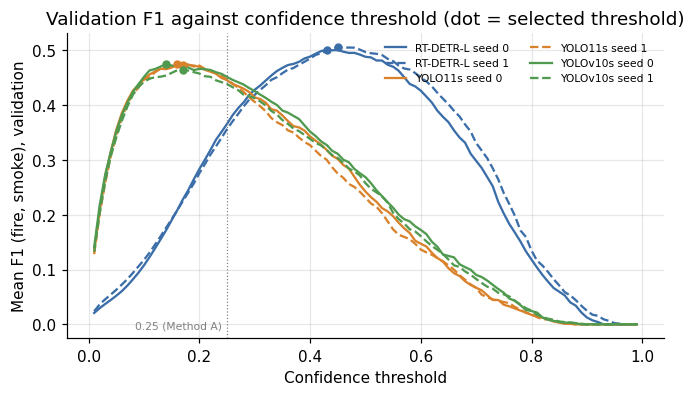

In [7]:
def tp_flags(pred, images, gt):
    groups = {k: g for k, g in pred.groupby("image")}
    out = []
    for im in images:
        g = gt[im]; gb, gcls = xywh2xyxy(g[:, 1:5]), g[:, 0].astype(int)
        d = groups.get(im)
        if d is None or len(d) == 0: continue
        d = d.sort_values("conf", ascending=False)
        db, dcls = xywh2xyxy(d[["cx", "cy", "w", "h"]].values), d.cls.values.astype(int)
        ious = iou_matrix(db, gb); matched = np.zeros(len(g), bool); tp = np.zeros(len(d), bool)
        for i in range(len(d)):
            cand = np.where((gcls == dcls[i]) & ~matched & (ious[i] >= IOU_MATCH))[0] if len(g) else []
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]; matched[j] = True; tp[i] = True
        out.append(pd.DataFrame({"cls": dcls, "conf": d.conf.values, "tp": tp}))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=["cls", "conf", "tp"])

GRID = np.round(np.arange(THRESH_GRID[0], THRESH_GRID[1] + 1e-9, THRESH_GRID[2]), 4)
n_gt_val = {c: int(sum((VAL_GT[im][:, 0] == c).sum() for im in VAL_IMAGES)) for c in range(len(CLASS_NAMES))}
THRESHOLDS, CURVES_F1, thr_rows = {}, {}, []
for key in sorted(PREDS["val"], key=lambda k: (MODEL_ORDER.index(k[0]) if k[0] in MODEL_ORDER else 9, k[1])):
    flags = tp_flags(PREDS["val"][key], VAL_IMAGES, VAL_GT)
    per_class = {}
    for c, cn in enumerate(CLASS_NAMES):
        fc = flags[flags.cls == c]; conf = fc.conf.values; tp = fc.tp.values.astype(bool)
        TP = np.array([int((tp & (conf >= t)).sum()) for t in GRID]); ND = np.array([int((conf >= t).sum()) for t in GRID])
        P = np.where(ND > 0, TP / np.maximum(ND, 1), np.nan); R = TP / max(n_gt_val[c], 1)
        P0 = np.nan_to_num(P); F = np.divide(2 * P0 * R, P0 + R, out=np.zeros_like(R, dtype=float), where=(P0 + R) > 0)
        per_class[cn] = (P, R, F)
    mean_f1 = np.mean([per_class[cn][2] for cn in CLASS_NAMES], axis=0)
    i = int(np.argmax(mean_f1)); THRESHOLDS[key] = float(GRID[i]); CURVES_F1[key] = mean_f1
    thr_rows.append({"model": key[0], "seed": key[1], "selected threshold": float(GRID[i]), "val mean F1": round(float(mean_f1[i]), 4),
                     **{f"val {k} {cn}": round(float(per_class[cn][j][i]), 4) for cn in CLASS_NAMES for j, k in enumerate(("precision", "recall", "F1"))},
                     "val mean F1 at 0.25": round(float(mean_f1[int(np.argmin(np.abs(GRID - CONF_THRESHOLD)))]), 4)})
thr_table = pd.DataFrame(thr_rows)
save_table(thr_table, "table_selected_thresholds_valbestf1", index=False)
print(f"Method B thresholds (best mean F1 of fire and smoke on the validation split, {len(VAL_IMAGES)} images):")
print(thr_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
for key, f1 in CURVES_F1.items():
    ax.plot(GRID, f1, color=COLORS.get(key[0]), ls="-" if key[1] == 0 else "--", lw=1.5, label=f"{key[0]} seed {key[1]}")
    ax.scatter([THRESHOLDS[key]], [f1[int(np.argmax(f1))]], color=COLORS.get(key[0]), s=20, zorder=3)
ax.axvline(CONF_THRESHOLD, color="grey", lw=0.8, ls=":")
ax.text(CONF_THRESHOLD - 0.01, 0.03, "0.25 (Method A)", fontsize=7, color="grey", ha="right", transform=ax.get_xaxis_transform())
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Mean F1 (fire, smoke), validation"); ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper right"); ax.set_title("Validation F1 against confidence threshold (dot = selected threshold)")
savefig(fig, "validation_f1_vs_threshold_valbestf1")

#### 4c. Matching on the test split

In [8]:
METHODS = {"fixed025": "Method A (fixed confidence 0.25)", "valbestf1": "Method B (validation best-F1 threshold)"}
METHOD_THR = {"fixed025": {k: CONF_THRESHOLD for k in PREDS["test"]}, "valbestf1": THRESHOLDS}
FPFN_ALL = {m: {k: fpfn_details(PREDS["test"][k], METHOD_THR[m][k]) for k in PREDS["test"]} for m in METHODS}

for m in METHODS:
    for k in PREDS["test"]:
        fl = tp_flags(PREDS["test"][k], TEST_IMAGES, GT)
        a = int((fl.tp & (fl.conf >= METHOD_THR[m][k])).sum()); b = int((FPFN_ALL[m][k][0].status == "TP").sum())
        assert a == b, f"TP mismatch for {k} ({m}): {a} vs {b}"
    print(f"{METHODS[m]}: matching done for {len(FPFN_ALL[m])} runs; TP counts agree with the one-pass matching")
for m in METHODS:
    for k, (D, G) in FPFN_ALL[m].items():
        D.to_csv(TAB / f"detections_{re.sub(r'[^a-z0-9]+', '_', k[0].lower())}_seed{k[1]}_{m}.csv", index=False)
        G.to_csv(TAB / f"ground_truth_{re.sub(r'[^a-z0-9]+', '_', k[0].lower())}_seed{k[1]}_{m}.csv", index=False)

Method A (fixed confidence 0.25): matching done for 6 runs; TP counts agree with the one-pass matching
Method B (validation best-F1 threshold): matching done for 6 runs; TP counts agree with the one-pass matching


#### 5. TP / FP / FN per model and class (full cleaned test split)

In [9]:
CNT, FPI = {}, {}
for M, mname in METHODS.items():
    FPFN = FPFN_ALL[M]
    cnt = []
    for (m, s), (D, G) in FPFN.items():
        for c, cn in enumerate(CLASS_NAMES):
            tp = int(((D.cls == c) & (D.status == "TP")).sum()); fp = int(((D.cls == c) & (D.status != "TP")).sum())
            fn = int(((G.cls == c) & (G.status != "found")).sum())
            p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn) if tp + fn else np.nan
            cnt.append({"model": m, "seed": s, "threshold": METHOD_THR[M][(m, s)], "class": cn, "TP": tp, "FP": fp, "FN": fn,
                        "precision": p, "recall": r, "F1": 2 * p * r / (p + r) if p + r else np.nan,
                        "miss rate": fn / (tp + fn) if tp + fn else np.nan})
    cnt = pd.DataFrame(cnt); save_table(cnt.round(4), f"fpfn_counts_per_run_{M}", index=False)
    rows = []
    for m in model_sort(cnt.model):
        for cn in CLASS_NAMES:
            s = cnt[(cnt.model == m) & (cnt["class"] == cn)]
            rows.append({"model": m, "class": cn, **{k: pm(s[k], 1) for k in ("TP", "FP", "FN")},
                         **{k: pm(s[k]) for k in ("precision", "recall", "F1", "miss rate")}})
    table_counts = pd.DataFrame(rows).set_index(["model", "class"])
    save_table(table_counts, f"table_fpfn_counts_{M}")
    print(f"{mname}: TP / FP / FN at IoU >= {IOU_MATCH} (mean ± std over seeds)\n" + table_counts.to_string())

    fpi = []
    for (m, s), (D, G) in FPFN.items():
        fpi.append({"model": m, "seed": s, "FP per image": (D.status != "TP").sum() / len(TEST_IMAGES),
                    "background FP per image": (D.status == "background").sum() / len(TEST_IMAGES)})
    fpi = pd.DataFrame(fpi)
    t = pd.DataFrame({c: [pm(fpi[fpi.model == m][c], 2) for m in model_sort(fpi.model)] for c in ("FP per image", "background FP per image")},
                     index=model_sort(fpi.model))
    save_table(t, f"table_fp_per_image_{M}"); print("\n" + t.to_string() + "\n")
    CNT[M], FPI[M] = cnt, fpi

Method A (fixed confidence 0.25): TP / FP / FN at IoU >= 0.5 (mean ± std over seeds)
                           TP              FP            FN      precision         recall             F1      miss rate
model     class                                                                                                        
RT-DETR-L fire   806.0 ± 21.2  2157.0 ± 202.2  277.0 ± 21.2  0.273 ± 0.013  0.744 ± 0.020  0.399 ± 0.012  0.256 ± 0.020
          smoke  571.5 ± 17.7   1984.0 ± 90.5  335.5 ± 17.7  0.224 ± 0.003  0.630 ± 0.019  0.330 ± 0.000  0.370 ± 0.019
YOLO11s   fire    402.0 ± 2.8    208.0 ± 11.3   681.0 ± 2.8  0.659 ± 0.014  0.371 ± 0.003  0.475 ± 0.006  0.629 ± 0.003
          smoke   306.0 ± 5.7    164.0 ± 12.7   601.0 ± 5.7  0.651 ± 0.013  0.337 ± 0.006  0.444 ± 0.002  0.663 ± 0.006
YOLOv10s  fire   429.0 ± 17.0    217.5 ± 17.7  654.0 ± 17.0  0.664 ± 0.009  0.396 ± 0.016  0.496 ± 0.010  0.604 ± 0.016
          smoke   309.0 ± 5.7     182.0 ± 5.7   598.0 ± 5.7  0.629 ± 0.003 

#### 6. Types of false positives and missed detections

Method A (fixed confidence 0.25): share of each error type (% of that model's FP or FN for the class, mean of seeds)
model                         RT-DETR-L  YOLO11s  YOLOv10s
kind class type                                           
FP   fire  background              29.6     10.6      11.7
           class confusion          0.1      1.0       0.0
           localization            59.7     73.8      76.1
           duplicate               10.6     14.7      12.2
     smoke background              25.5     22.0      20.3
           class confusion          0.3      0.0       0.3
           localization            51.2     61.6      65.4
           duplicate               23.1     16.5      14.0
FN   fire  missed completely       28.5     74.6      73.9
           class confusion          0.7      0.0       0.0
           localization            70.8     25.4      26.1
     smoke missed completely       33.1     70.0      68.8
           class confusion          0.4      0.3       0.

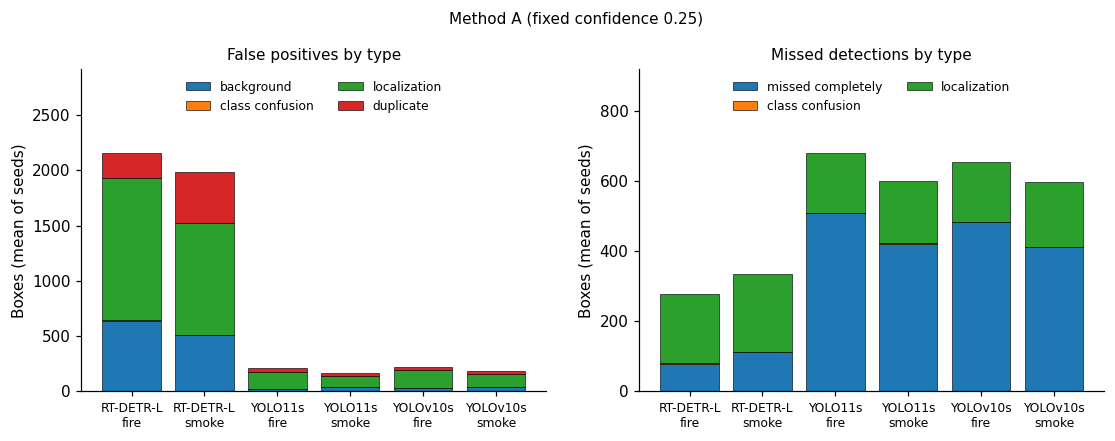

Method B (validation best-F1 threshold): share of each error type (% of that model's FP or FN for the class, mean of seeds)
model                         RT-DETR-L  YOLO11s  YOLOv10s
kind class type                                           
FP   fire  background              23.3     13.5      13.5
           class confusion          0.2      0.4       0.2
           localization            70.2     69.0      67.7
           duplicate                6.2     17.0      18.5
     smoke background              23.5     19.6      19.4
           class confusion          0.0      0.3       0.4
           localization            60.1     60.7      58.7
           duplicate               16.5     19.4      21.5
FN   fire  missed completely       55.3     58.8      55.8
           class confusion          0.0      0.2       0.2
           localization            44.7     41.0      44.0
     smoke missed completely       54.0     57.2      55.9
           class confusion          0.2      0.4  

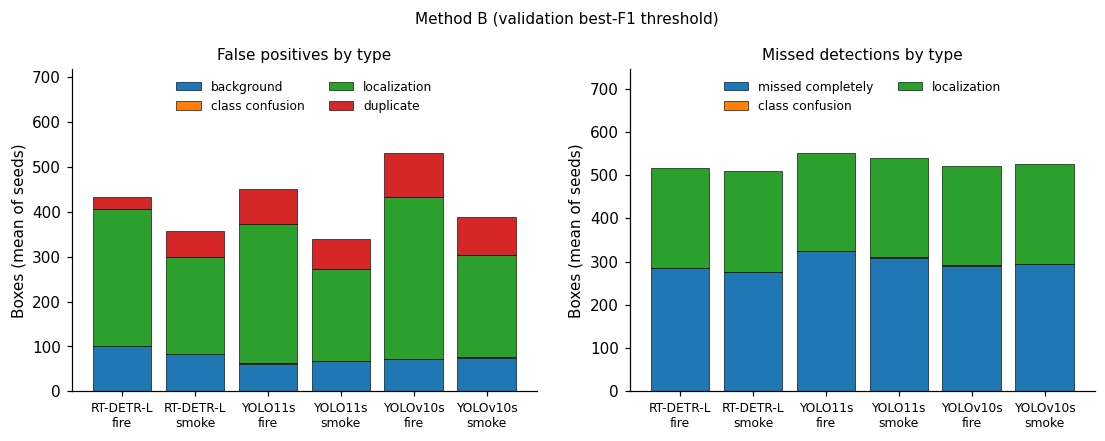

In [10]:
ETM = {}
for M, mname in METHODS.items():
    FPFN = FPFN_ALL[M]
    et = []
    for (m, s), (D, G) in FPFN.items():
        r = {"model": m, "seed": s}
        for c, cn in enumerate(CLASS_NAMES):
            for t_ in FP_TYPES: r[f"FP {cn}: {t_}"] = int(((D.cls == c) & (D.status == t_)).sum())
            for t_ in FN_TYPES: r[f"FN {cn}: {t_}"] = int(((G.cls == c) & (G.status == t_)).sum())
        et.append(r)
    et = pd.DataFrame(et); save_table(et, f"error_types_per_run_{M}", index=False)
    etm = et.groupby("model").mean(numeric_only=True).drop(columns="seed").reindex(model_sort(et.model))
    save_table(etm.round(1), f"table_error_types_{M}")
    share = {}
    for kind, types in (("FP", FP_TYPES), ("FN", FN_TYPES)):
        for cn in CLASS_NAMES:
            cols = [f"{kind} {cn}: {t_}" for t_ in types]
            tot = etm[cols].sum(axis=1)
            for t_ in types:
                share[(kind, cn, t_)] = (100 * etm[f"{kind} {cn}: {t_}"] / tot).round(1)
    share = pd.DataFrame(share).T
    share.index.names = ["kind", "class", "type"]
    save_table(share, f"table_error_types_percent_{M}")
    print(f"{mname}: share of each error type (% of that model's FP or FN for the class, mean of seeds)\n" + share.to_string() + "\n")

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for k, (kind, types) in enumerate([("FP", FP_TYPES), ("FN", FN_TYPES)]):
        labels = [f"{m}\n{cn}" for m in etm.index for cn in CLASS_NAMES]; bottom = np.zeros(len(labels))
        for t_ in types:
            v = np.array([etm.loc[m, f"{kind} {cn}: {t_}"] for m in etm.index for cn in CLASS_NAMES])
            ax[k].bar(labels, v, bottom=bottom, label=t_, edgecolor="black", linewidth=0.4); bottom += v
        ax[k].set_title("False positives by type" if kind == "FP" else "Missed detections by type", fontsize=10)
        ax[k].set_ylim(0, bottom.max() * 1.35)
        ax[k].set_ylabel("Boxes (mean of seeds)"); ax[k].legend(frameon=False, fontsize=8, ncol=2, loc="upper center"); ax[k].tick_params(axis="x", labelsize=8)
    fig.suptitle(mname, fontsize=10, y=1.02)
    savefig(fig, f"error_types_{M}")
    ETM[M] = etm

#### 7. Errors under challenging conditions

Method A (fixed confidence 0.25)
                                    images miss rate fire miss rate smoke  FP per image background FP per image
group                    model                                                                                 
Full cleaned test        RT-DETR-L     782  0.256 ± 0.020   0.370 ± 0.019   5.30 ± 0.37             1.46 ± 0.17
                         YOLO11s       782  0.629 ± 0.003   0.663 ± 0.006   0.48 ± 0.00             0.07 ± 0.01
                         YOLOv10s      782  0.604 ± 0.016   0.659 ± 0.006   0.51 ± 0.02             0.08 ± 0.00
Challenging sample (all) RT-DETR-L     197  0.369 ± 0.015   0.371 ± 0.046   8.05 ± 0.87             2.31 ± 0.53
                         YOLO11s       197  0.825 ± 0.015   0.686 ± 0.002   0.56 ± 0.00             0.15 ± 0.00
                         YOLOv10s      197  0.810 ± 0.002   0.678 ± 0.010   0.60 ± 0.03             0.14 ± 0.01
Weak / Diffuse Smoke     RT-DETR-L      89  0.295 ± 0.007   0.338 ± 0.0

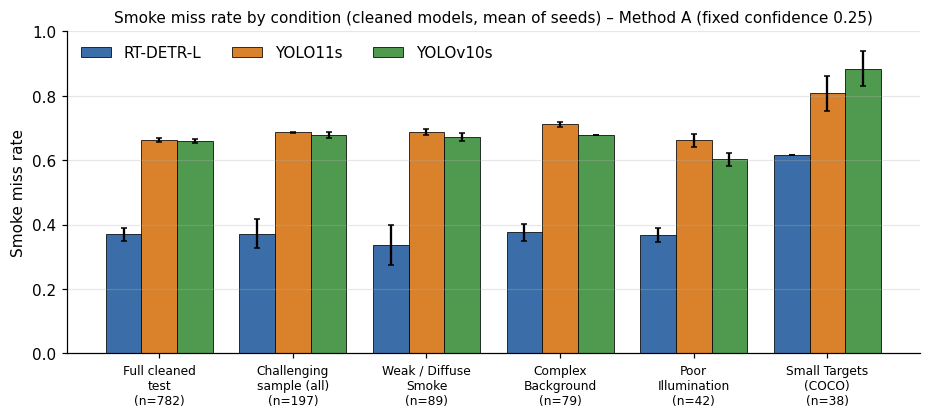

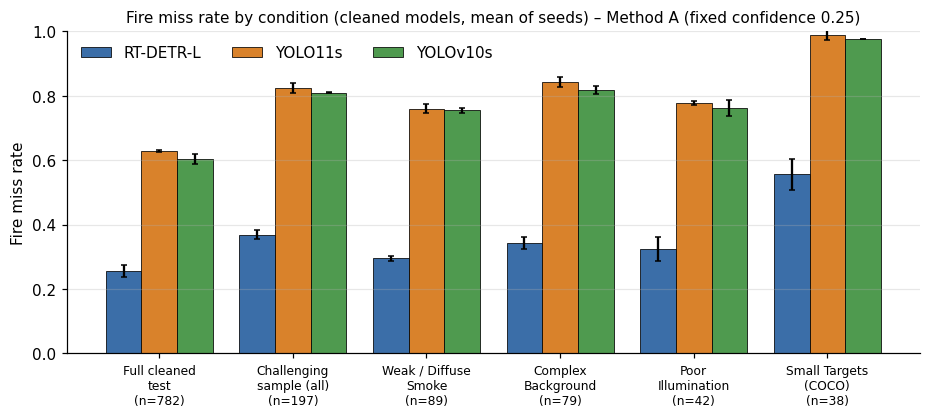

Method B (validation best-F1 threshold)
                                    images miss rate fire miss rate smoke FP per image background FP per image
group                    model                                                                                
Full cleaned test        RT-DETR-L     782  0.477 ± 0.030   0.562 ± 0.012  1.01 ± 0.16             0.24 ± 0.05
                         YOLO11s       782  0.509 ± 0.007   0.595 ± 0.009  1.01 ± 0.09             0.16 ± 0.01
                         YOLOv10s      782  0.482 ± 0.031   0.580 ± 0.028  1.18 ± 0.21             0.19 ± 0.03
Challenging sample (all) RT-DETR-L     197  0.624 ± 0.050   0.585 ± 0.041  1.49 ± 0.31             0.39 ± 0.13
                         YOLO11s       197  0.683 ± 0.000   0.605 ± 0.012  1.29 ± 0.17             0.26 ± 0.02
                         YOLOv10s      197  0.661 ± 0.046   0.595 ± 0.031  1.44 ± 0.20             0.31 ± 0.05
Weak / Diffuse Smoke     RT-DETR-L      89  0.575 ± 0.106   0.578 ± 0.04

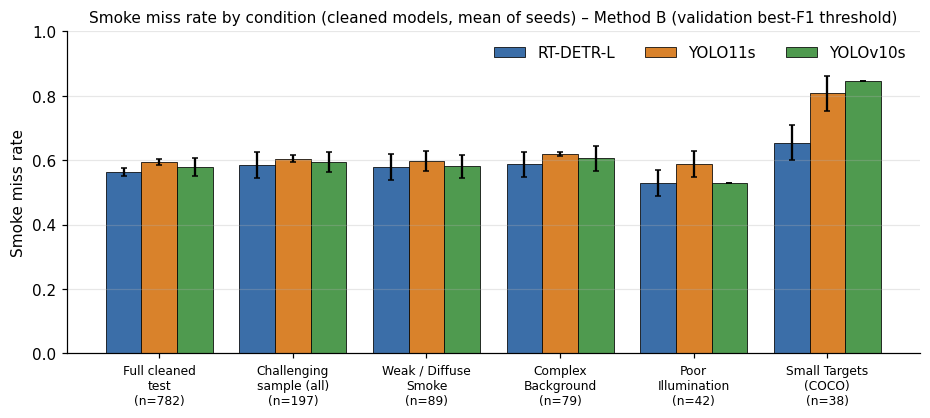

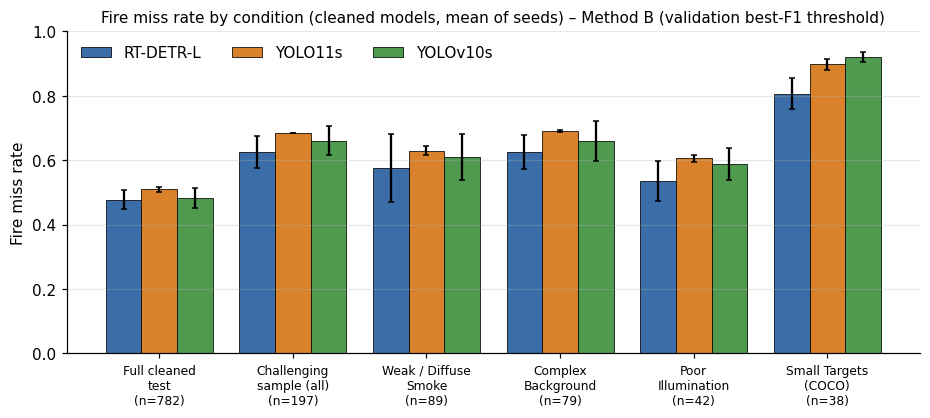

In [11]:
WR = {}
for M, mname in METHODS.items():
    FPFN = FPFN_ALL[M]
    wr = []
    for (m, s), (D, G) in FPFN.items():
        for g, ims in GROUPS.items():
            Gi = G[G.small] if g == "Small Targets (COCO)" else G[G.image.isin(ims)]
            Di = D[D.image.isin(ims)]
            r = {"group": g, "model": m, "seed": s, "images": len(ims)}
            for c, cn in enumerate(CLASS_NAMES):
                gc = Gi[Gi.cls == c]
                r[f"miss rate {cn}"] = (gc.status != "found").mean() if len(gc) else np.nan
            r["FP per image"] = np.nan if g == "Small Targets (COCO)" else (Di.status != "TP").sum() / max(len(ims), 1)
            r["background FP per image"] = np.nan if g == "Small Targets (COCO)" else (Di.status == "background").sum() / max(len(ims), 1)
            wr.append(r)
    wr = pd.DataFrame(wr); save_table(wr.round(4), f"fpfn_by_condition_per_run_{M}", index=False)
    rows = []
    for g in GROUPS:
        for m in model_sort(wr.model):
            s = wr[(wr.group == g) & (wr.model == m)]
            rows.append({"group": g, "model": m, "images": int(s.images.iloc[0]),
                         "miss rate fire": pm(s["miss rate fire"]), "miss rate smoke": pm(s["miss rate smoke"]),
                         "FP per image": pm(s["FP per image"], 2), "background FP per image": pm(s["background FP per image"], 2)})
    table_cond = pd.DataFrame(rows).set_index(["group", "model"])
    save_table(table_cond, f"table_fpfn_by_condition_{M}")
    print(f"{mname}\n" + table_cond.to_string() + "\n")

    for col, name, ttl in [("miss rate smoke", "smoke_miss_rate_by_condition", "Smoke miss rate"),
                           ("miss rate fire", "fire_miss_rate_by_condition", "Fire miss rate")]:
        piv = wr.groupby(["group", "model"])[col].mean().unstack("model").reindex(list(GROUPS))
        piv = piv[model_sort(piv.columns)]
        fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(piv)); w = 0.8 / max(len(piv.columns), 1)
        for k, m in enumerate(piv.columns):
            sd = wr[wr.model == m].groupby("group")[col].std().reindex(piv.index)
            ax.bar(x + (k - (len(piv.columns) - 1) / 2) * w, piv[m].values, w, yerr=np.nan_to_num(sd.values), capsize=2,
                   label=m, color=COLORS.get(m), edgecolor="black", linewidth=0.5)
        ax.set_xticks(x, [textwrap.fill(g, 14) + f"\n(n={len(GROUPS[g])})" for g in piv.index], fontsize=8)
        ax.set_ylabel(ttl); ax.set_ylim(0, 1); ax.legend(frameon=False, ncol=3); ax.grid(axis="y", alpha=0.3)
        ax.set_title(f"{ttl} by condition (cleaned models, mean of seeds) – {mname}", fontsize=10)
        savefig(fig, f"{name}_{M}")
    WR[M] = wr

#### 8. Comparison of the two methods

Full cleaned test split: Method A vs Method B (mean of seeds)
                                                  threshold (seed 0 / seed 1)  precision fire  recall fire  F1 fire  FP fire  FN fire  precision smoke  recall smoke  F1 smoke  FP smoke  FN smoke  FP per image
model     method                                                                                                                                                                                                
RT-DETR-L Method A (fixed confidence 0.25)                        0.25 / 0.25           0.273        0.744    0.399   2157.0    277.0            0.224         0.630     0.330    1984.0     335.5          5.30
          Method B (validation best-F1 threshold)                 0.43 / 0.45           0.568        0.523    0.544    433.0    517.0            0.527         0.438     0.478     358.0     510.0          1.01
YOLO11s   Method A (fixed confidence 0.25)                        0.25 / 0.25           0.659        0

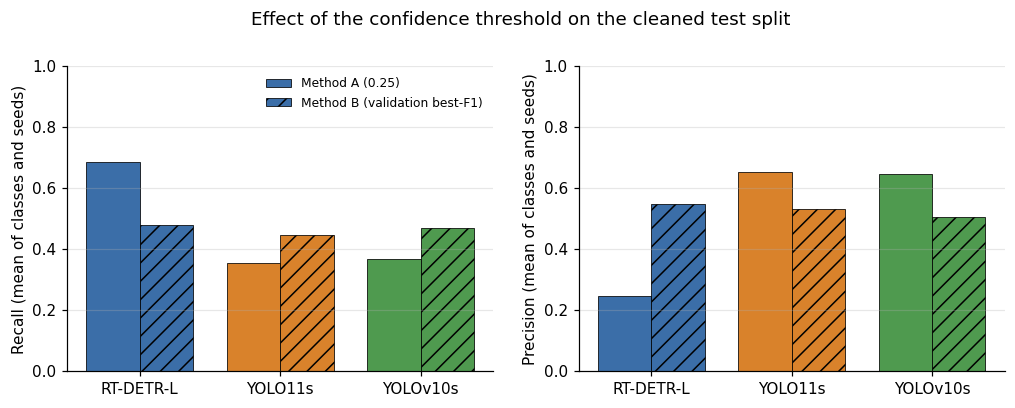

In [12]:
cmp_rows = []
for m in model_sort(CNT["fixed025"].model):
    for M, mname in METHODS.items():
        c_ = CNT[M][CNT[M].model == m]; f_ = FPI[M][FPI[M].model == m]
        row = {"model": m, "method": mname,
               "threshold (seed 0 / seed 1)": " / ".join(f"{METHOD_THR[M][(m, s)]:.2f}" for s in SEEDS if (m, s) in METHOD_THR[M])}
        for cn in CLASS_NAMES:
            cc = c_[c_["class"] == cn]
            row.update({f"precision {cn}": round(cc.precision.mean(), 3), f"recall {cn}": round(cc.recall.mean(), 3),
                        f"F1 {cn}": round(cc.F1.mean(), 3), f"FP {cn}": round(cc.FP.mean(), 1), f"FN {cn}": round(cc.FN.mean(), 1)})
        row["FP per image"] = round(f_["FP per image"].mean(), 2)
        cmp_rows.append(row)
table_cmp = pd.DataFrame(cmp_rows).set_index(["model", "method"])
save_table(table_cmp, "table_method_comparison_full_test")
print("Full cleaned test split: Method A vs Method B (mean of seeds)\n" + table_cmp.to_string())

ccmp = []
for g in GROUPS:
    for m in model_sort(WR["fixed025"].model):
        row = {"group": g, "model": m, "images": len(GROUPS[g])}
        for M in METHODS:
            w_ = WR[M][(WR[M].group == g) & (WR[M].model == m)]
            row[f"miss rate fire ({M})"] = round(w_["miss rate fire"].mean(), 3)
            row[f"miss rate smoke ({M})"] = round(w_["miss rate smoke"].mean(), 3)
            row[f"FP per image ({M})"] = round(w_["FP per image"].mean(), 2) if g != "Small Targets (COCO)" else np.nan
        ccmp.append(row)
table_ccmp = pd.DataFrame(ccmp).set_index(["group", "model"])
save_table(table_ccmp, "table_method_comparison_by_condition")
print("\nChallenging conditions: Method A (fixed025) vs Method B (valbestf1), mean of seeds\n" + table_ccmp.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
models = model_sort(CNT["fixed025"].model); x = np.arange(len(models)); w = 0.38
for ax, (col, lab) in zip(axes, [("recall", "Recall"), ("precision", "Precision")]):
    for k, (M, hatch) in enumerate([("fixed025", ""), ("valbestf1", "//")]):
        v = [CNT[M][CNT[M].model == m][col].mean() for m in models]
        ax.bar(x + (k - 0.5) * w, v, w, hatch=hatch, color=[COLORS.get(m) for m in models], edgecolor="black", linewidth=0.5,
               label="Method A (0.25)" if M == "fixed025" else "Method B (validation best-F1)")
    ax.set_xticks(x, models); ax.set_ylim(0, 1); ax.set_ylabel(f"{lab} (mean of classes and seeds)"); ax.grid(axis="y", alpha=0.3)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Effect of the confidence threshold on the cleaned test split", y=1.02)
savefig(fig, "method_comparison_precision_recall")

#### 9. Example images

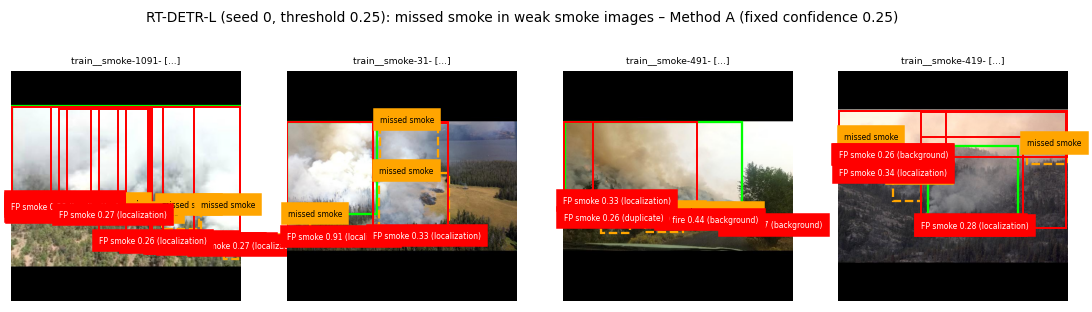

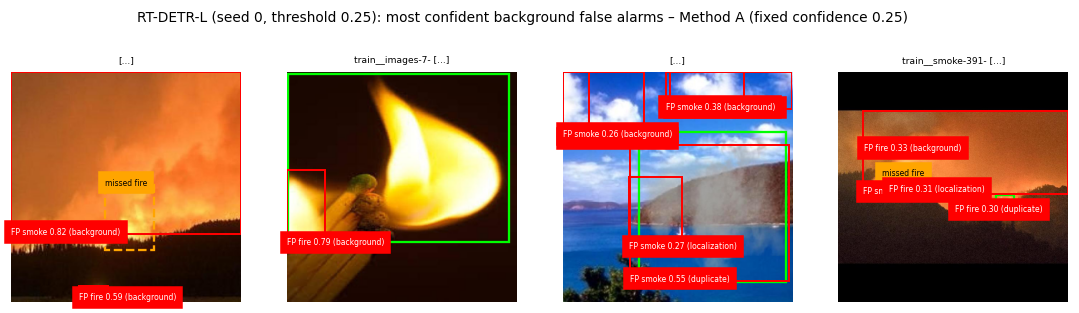

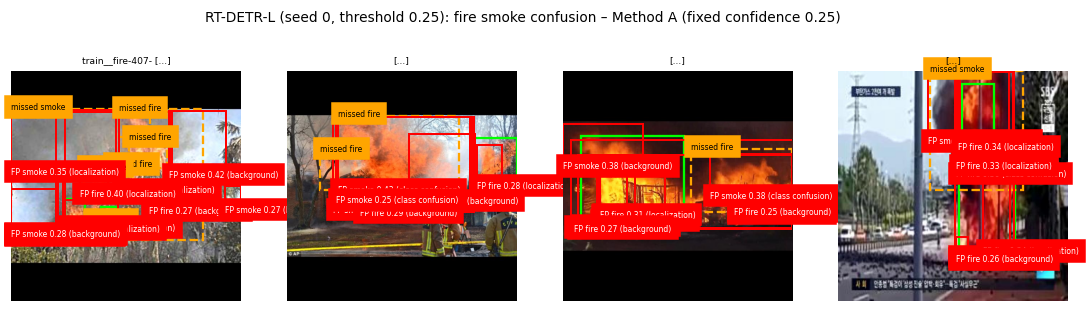

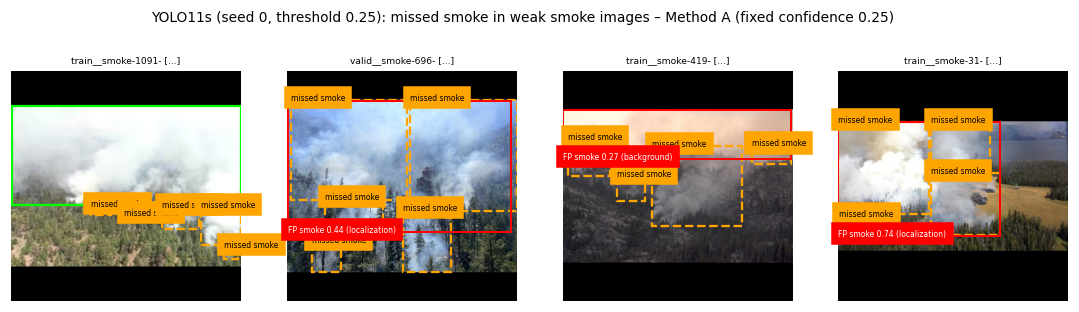

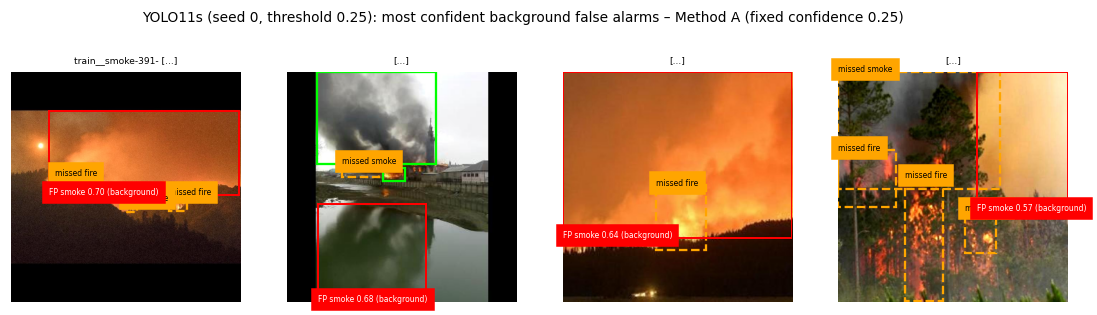

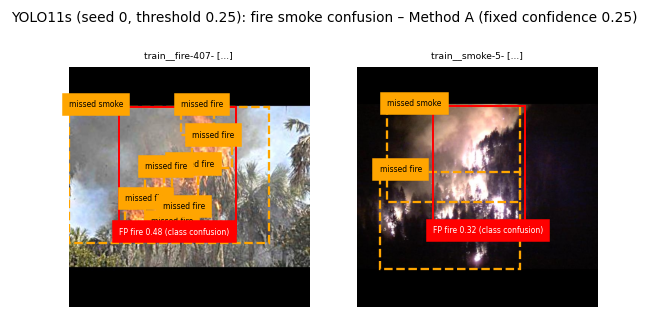

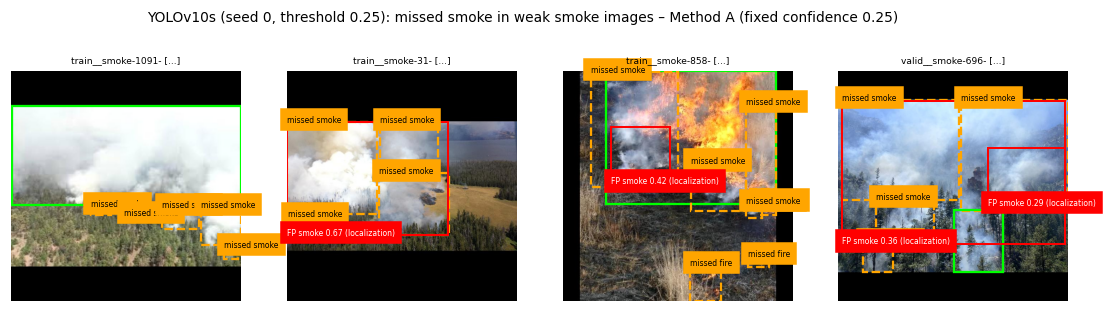

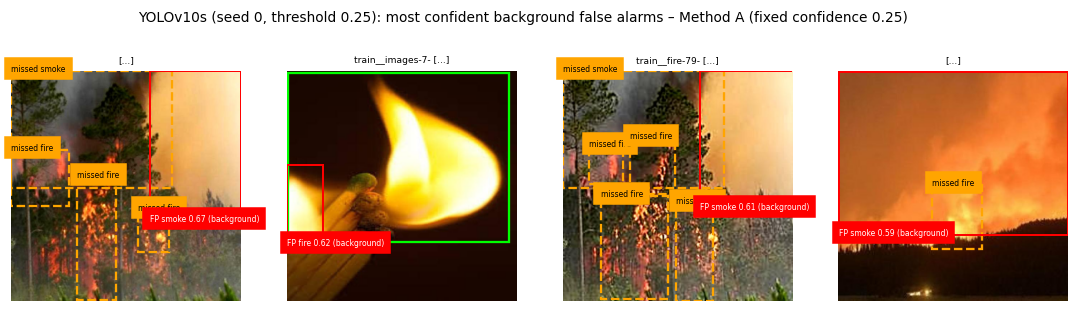

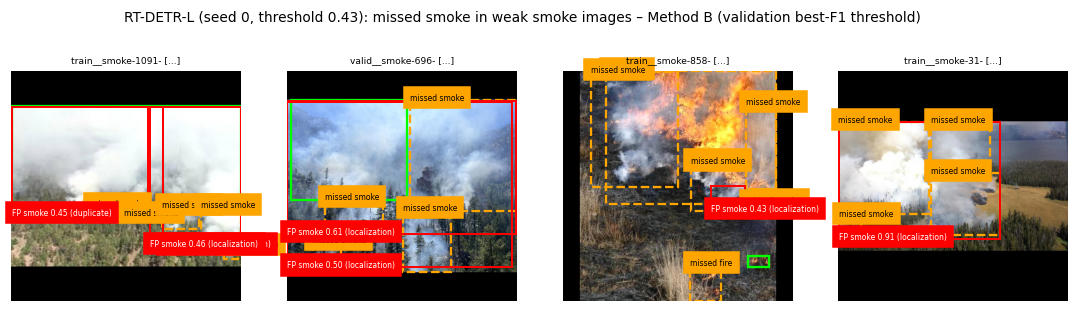

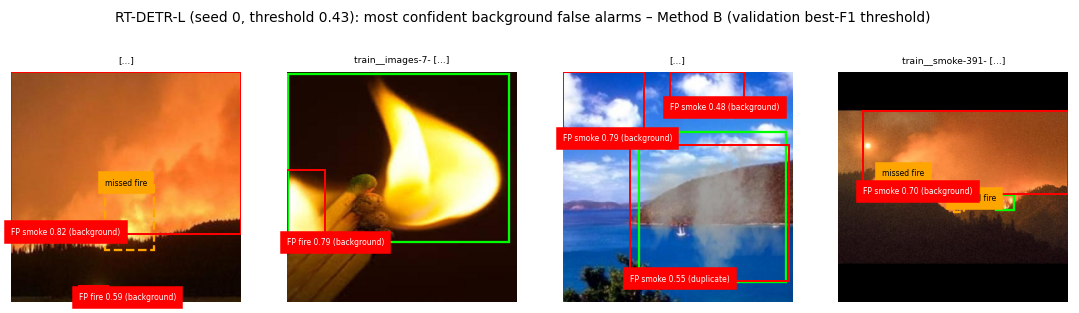

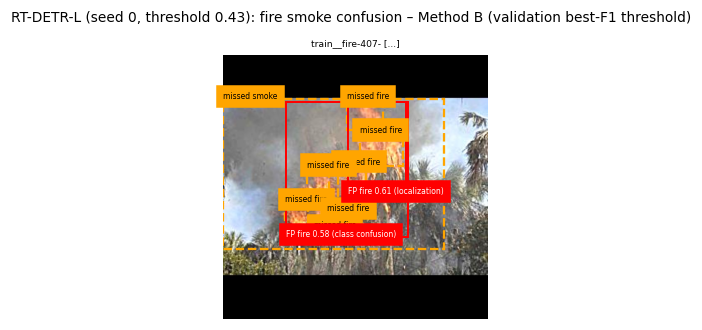

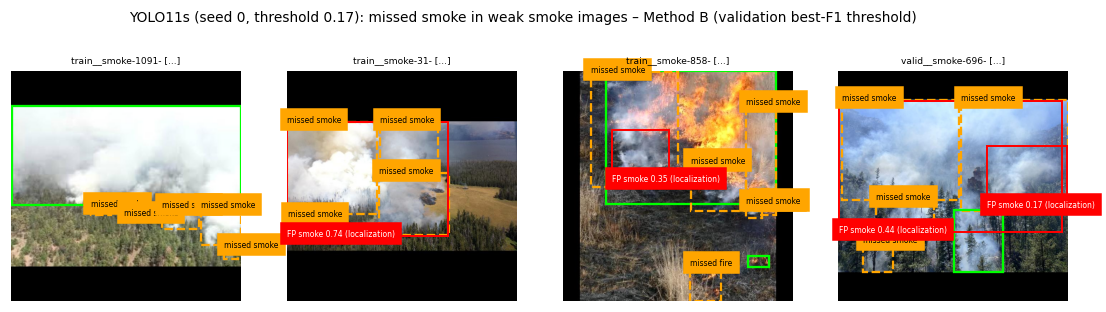

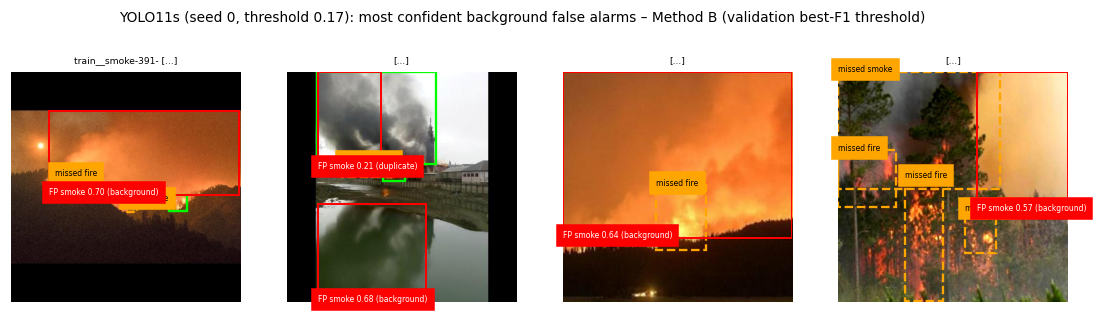

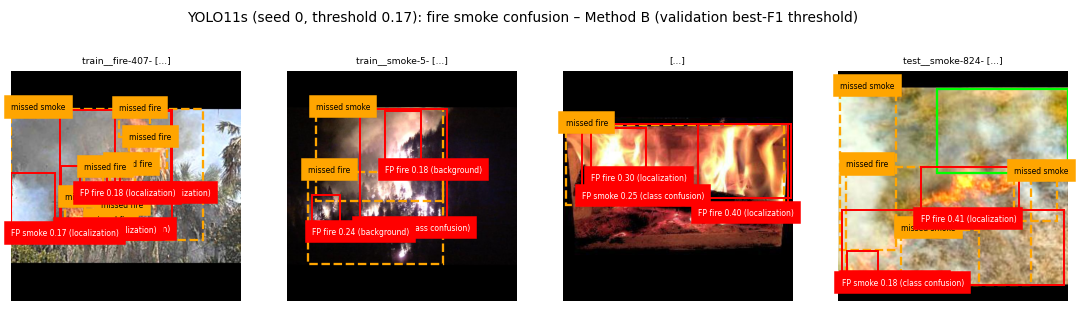

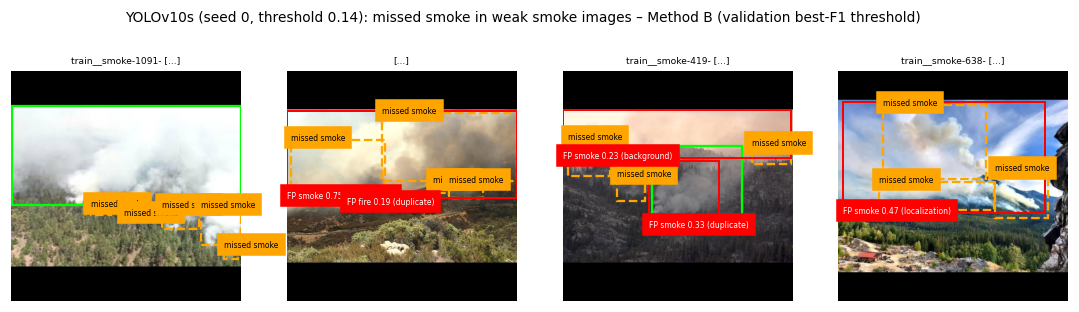

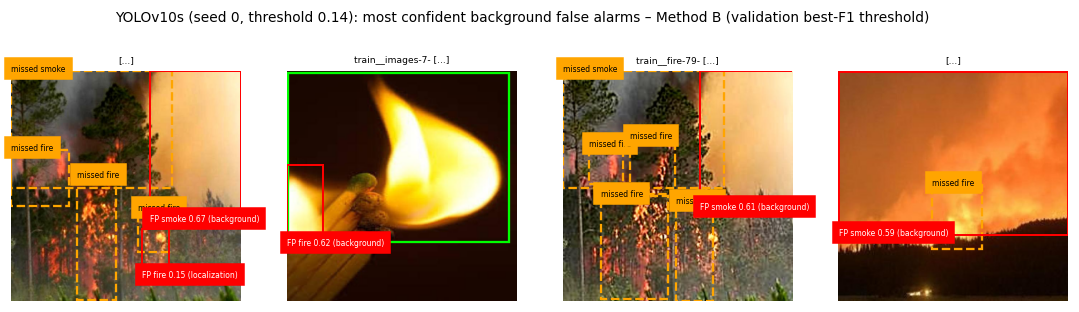

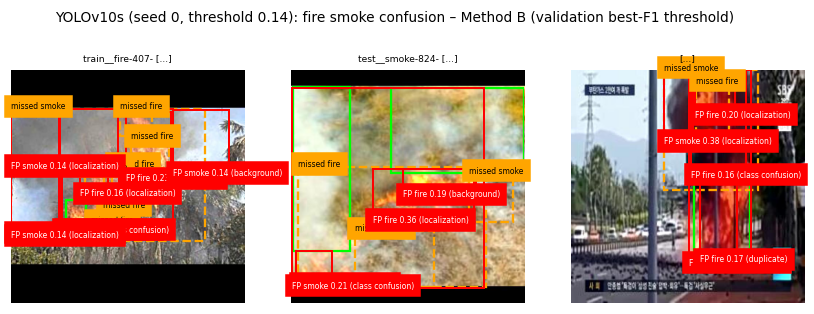

In [13]:
def draw(ax, im, D, G):
    img = Image.open(TEST_IMG / im); W, H = img.size; ax.imshow(img); ax.axis("off")
    for g in G[G.image == im].itertuples():
        x1, y1 = (g.cx - g.w / 2) * W, (g.cy - g.h / 2) * H; ok = g.status == "found"
        ax.add_patch(mpatches.Rectangle((x1, y1), g.w * W, g.h * H, fill=False, lw=1.5, ec="lime" if ok else "orange", ls="-" if ok else "--"))
        if not ok: ax.text(x1, y1, f"missed {CLASS_NAMES[g.cls]}", fontsize=5, color="k", backgroundcolor="orange")
    for d in D[(D.image == im) & (D.status != "TP")].itertuples():
        x1, y1 = (d.cx - d.w / 2) * W, (d.cy - d.h / 2) * H
        ax.add_patch(mpatches.Rectangle((x1, y1), d.w * W, d.h * H, fill=False, lw=1.3, ec="red"))
        ax.text(x1, y1 + d.h * H, f"FP {CLASS_NAMES[d.cls]} {d.conf:.2f} ({d.status})", fontsize=5, color="w", backgroundcolor="red")
    ax.set_title(textwrap.shorten(im, 34), fontsize=6)

def gallery(images, key, title, M):
    images = list(images)[:N_EXAMPLES]
    if not images: return
    D, G = FPFN_ALL[M][key]
    fig, axs = plt.subplots(1, len(images), figsize=(3.1 * len(images), 3.3), squeeze=False)
    for ax, im in zip(axs[0], images): draw(ax, im, D, G)
    fig.suptitle(f"{key[0]} (seed {key[1]}, threshold {METHOD_THR[M][key]:.2f}): {title} – {METHODS[M]}", fontsize=9)
    fig.savefig(EXM / f"{re.sub(r'[^a-z0-9]+', '_', key[0].lower())}_seed{key[1]}_{re.sub(r'[^a-z0-9]+', '_', title.lower())}_{M}.png",
                dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

weak = GROUPS.get("Weak / Diffuse Smoke", TEST_IMAGES)
for M in METHODS:
    for m in MODEL_ORDER:
        key = (m, EXAMPLE_SEED)
        if key not in FPFN_ALL[M]: continue
        D, G = FPFN_ALL[M][key]
        miss = G[(G.cls == 1) & (G.status != "found") & G.image.isin(weak)].groupby("image").size().sort_values(ascending=False)
        gallery(miss.index, key, "missed smoke in weak smoke images" if "Weak / Diffuse Smoke" in GROUPS else "missed smoke", M)
        bg = D[D.status == "background"].sort_values("conf", ascending=False).drop_duplicates("image")
        gallery(bg.image, key, "most confident background false alarms", M)
        cc = D[D.status == "class confusion"].sort_values("conf", ascending=False).drop_duplicates("image")
        gallery(cc.image, key, "fire smoke confusion", M)

#### 10. Summary of key results

In [14]:
print(f"IoU >= {IOU_MATCH}; small object < {SMALL_AREA_PX} px^2; predictions stored down to confidence {PRED_CONF}")
for M, mname in METHODS.items():
    print(f"\n{mname}")
    cnt, fpi, wr = CNT[M], FPI[M], WR[M]
    g = cnt.groupby(["model", "class"])[["recall", "miss rate", "precision"]].mean()
    for m in model_sort(cnt.model):
        thr = " / ".join(f"{METHOD_THR[M][(m, s)]:.2f}" for s in SEEDS if (m, s) in METHOD_THR[M])
        print(f"- {m} (threshold {thr}): miss rate fire {g.at[(m, 'fire'), 'miss rate']:.3f}, smoke {g.at[(m, 'smoke'), 'miss rate']:.3f}; "
              f"FP per image {fpi[fpi.model == m]['FP per image'].mean():.2f}")
    if "Weak / Diffuse Smoke" in GROUPS:
        a = wr[wr.group == "Weak / Diffuse Smoke"].groupby("model")["miss rate smoke"].mean()
        b = wr[wr.group == "Full cleaned test"].groupby("model")["miss rate smoke"].mean()
        print("- smoke miss rate, weak smoke vs full test:", {m: f"{a[m]:.3f} vs {b[m]:.3f}" for m in model_sort(a.index)})
print("\nFILES")
for sub in (TAB, FIG, EXM):
    files = sorted(p.name for p in sub.iterdir() if p.is_file())
    print(f"{sub.name}/ ({len(files)})"); print("   " + "\n   ".join(files) if files else "   -")

IoU >= 0.5; small object < 1024 px^2; predictions stored down to confidence 0.001

Method A (fixed confidence 0.25)
- RT-DETR-L (threshold 0.25 / 0.25): miss rate fire 0.256, smoke 0.370; FP per image 5.30
- YOLO11s (threshold 0.25 / 0.25): miss rate fire 0.629, smoke 0.663; FP per image 0.48
- YOLOv10s (threshold 0.25 / 0.25): miss rate fire 0.604, smoke 0.659; FP per image 0.51
- smoke miss rate, weak smoke vs full test: {'RT-DETR-L': '0.338 vs 0.370', 'YOLO11s': '0.688 vs 0.663', 'YOLOv10s': '0.672 vs 0.659'}

Method B (validation best-F1 threshold)
- RT-DETR-L (threshold 0.43 / 0.45): miss rate fire 0.477, smoke 0.562; FP per image 1.01
- YOLO11s (threshold 0.17 / 0.16): miss rate fire 0.509, smoke 0.595; FP per image 1.01
- YOLOv10s (threshold 0.14 / 0.17): miss rate fire 0.482, smoke 0.580; FP per image 1.18
- smoke miss rate, weak smoke vs full test: {'RT-DETR-L': '0.578 vs 0.562', 'YOLO11s': '0.597 vs 0.595', 'YOLOv10s': '0.581 vs 0.580'}

FILES
tables/ (44)
   condition_groups